# 3.4 · Wheel movement clusters

Segments the wheel into **whole movements** and clusters them -- not to be confused with 3.3's wheel *wavelet* clusters (`VAR = 'wheel'`), which label every frame from its wavelet power. The code is in `wheel_movement_clusters.py` (its header explains every step); the exploration behind the choices is in `representation_learning/wheel_movements/` (notebooks 4-7).

1. **Movements**: IBL's `wheelMoves` intervals, ±50 ms, cached with the trials (`python wheel_movement_clusters.py fetch proficient`).
2. **Shape**: signed wheel velocity in rad/s (not divided by the peak, so vigor is part of the shape), time-normalised to 200 bins.
3. **Fit**: 2000 movements per mouse of the LDA cohort, split equally across its sessions; PCA to 95 % + log duration; movements split by travel balance into −side / balanced / +side, one Gaussian mixture each (7 / 6 / 7 clusters).
4. **Description**: per cluster, the stimulus side it reports (wheel sign measured on correct response-epoch movements), vigor (median peak speed) and jitter (direction reversals); clusters numbered left → both → right by vigor.
5. **States**: every design-matrix frame gets 0 = not in a movement ('still') or its movement's state. Written for three state sets, in 3.3's file layout, so `syllable_pipeline` reads them with `WHEEL_SEGMENTATION = 'movement'` and `K_WHEEL` = the number of states including still:

| `K_WHEEL` | grouping | states |
|---|---|---|
| 21 | none | still + the 20 clusters |
| 10 | `side_vigor` | still + left / both / right × low / mid / high |
| 17 | `sided_both2` | still + the 14 one-sided clusters + balanced low / high |

In [1]:
DATASET = 'proficient'
WRITE = True          # write the states files
OVERWRITE = False     # recompute states files that already exist
N_JOBS = 8

In [2]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import importlib, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from joblib import Parallel, delayed
import wheel_movement_clusters as wmc
import syllable_pipeline as sp
importlib.reload(wmc)
sys.path.insert(0, wmc.PI)
import paper_style as ps
ps.use('paper', dpi=110)

coh = wmc.fit_cohort()
out = Parallel(n_jobs=12)(delayed(wmc.session_shapes)(DATASET, m, e) for m, e in zip(coh.mouse, coh.eid))
ALL_S = {e: s for (s, _), e in zip(out, coh.eid)}
ALL_I = {e: i for (_, i), e in zip(out, coh.eid)}
S, info = wmc.sample(coh, ALL_S, ALL_I)
print(f'fit cohort: {len(coh)} sessions, {coh.mouse.nunique()} mice, {sum(len(i) for i in ALL_I.values()):,} movements; '
      f'fit sample {len(info):,} ({info.groupby("mouse").size().min()}-{info.groupby("mouse").size().max()} per mouse)')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


fit cohort: 269 sessions, 58 mice, 391,651 movements; fit sample 116,056 (2000-2007 per mouse)


## Fit

In [3]:
model = wmc.fit(S, info)
wmc.save_model(DATASET, model)
info['cluster'] = wmc.predict(model, S, info.duration)
print(f"{model['n_pc']} PCs ({wmc.VAR:.0%} variance);  + wheel reports right with p = {model['sign_check']['p_pos_given_right']:.2f} "
      f"(vs {model['sign_check']['p_pos_given_left']:.2f} for left stimuli) -> SIGN_RIGHT = {model['SIGN_RIGHT']}")
model['desc'].round(2)

15 PCs (95% variance);  + wheel reports right with p = 0.82 (vs 0.18 for left stimuli) -> SIGN_RIGHT = 1


,mixture_label,fraction,side_index,peak_rad_s,reversals,duration_s,response,post_feedback,side,vigor,jitter,label
cluster,,,,,,,,,,,,
0,3,0.03,-1.00,0.24,0.0,0.10,0.15,0.67,left,low,smooth,left low smooth
1,0,0.03,-1.00,0.51,0.0,0.21,0.17,0.66,left,low,smooth,left low smooth
2,6,0.04,-0.92,1.21,1.0,0.38,0.31,0.49,left,mid,smooth,left mid smooth
3,2,0.05,-0.87,2.29,1.0,0.58,0.43,0.31,left,mid,smooth,left mid smooth
4,5,0.06,-0.76,2.95,2.0,1.00,0.57,0.20,left,high,corrective,left high corrective
5,1,0.02,-0.95,3.09,1.0,0.81,0.76,0.10,left,high,smooth,left high smooth
6,4,0.04,-0.69,4.25,4.0,1.74,0.63,0.17,left,high,jittery,left high jittery
7,8,0.03,-0.00,0.35,1.0,0.15,0.21,0.67,both,low,smooth,both low smooth
8,7,0.05,-0.01,0.65,2.0,0.37,0.22,0.58,both,low,corrective,both low corrective


In [4]:
# same procedure as the prototype (representation_learning/wheel_movements/5b): it must give the same clusters
proto = wmc.PI + 'data/wheel_movements_proficient/model_absolute.pkl'
if os.path.exists(proto):
    import pickle
    P = pickle.load(open(proto, 'rb'))
    F = (np.column_stack([P['pca'].transform(S)[:, :P['n_pc']], np.log10(info.duration)]) - P['MU']) / P['SD']
    g = wmc.side_group(S, P['SPLIT'])
    raw = np.empty(len(S), int)
    for k in range(3):
        raw[g == k] = P['GM'][k].predict(F[g == k]) + P['OFF'][k]
    same = np.mean(np.array([P['REL'][r] for r in raw]) == info.cluster)
    print(f'clusters identical to the prototype for {same:.2%} of the fit sample')

clusters identical to the prototype for 100.00% of the fit sample


## The 20 clusters (absolute velocity; 60 random members thin, median thick; x = fraction of the movement)

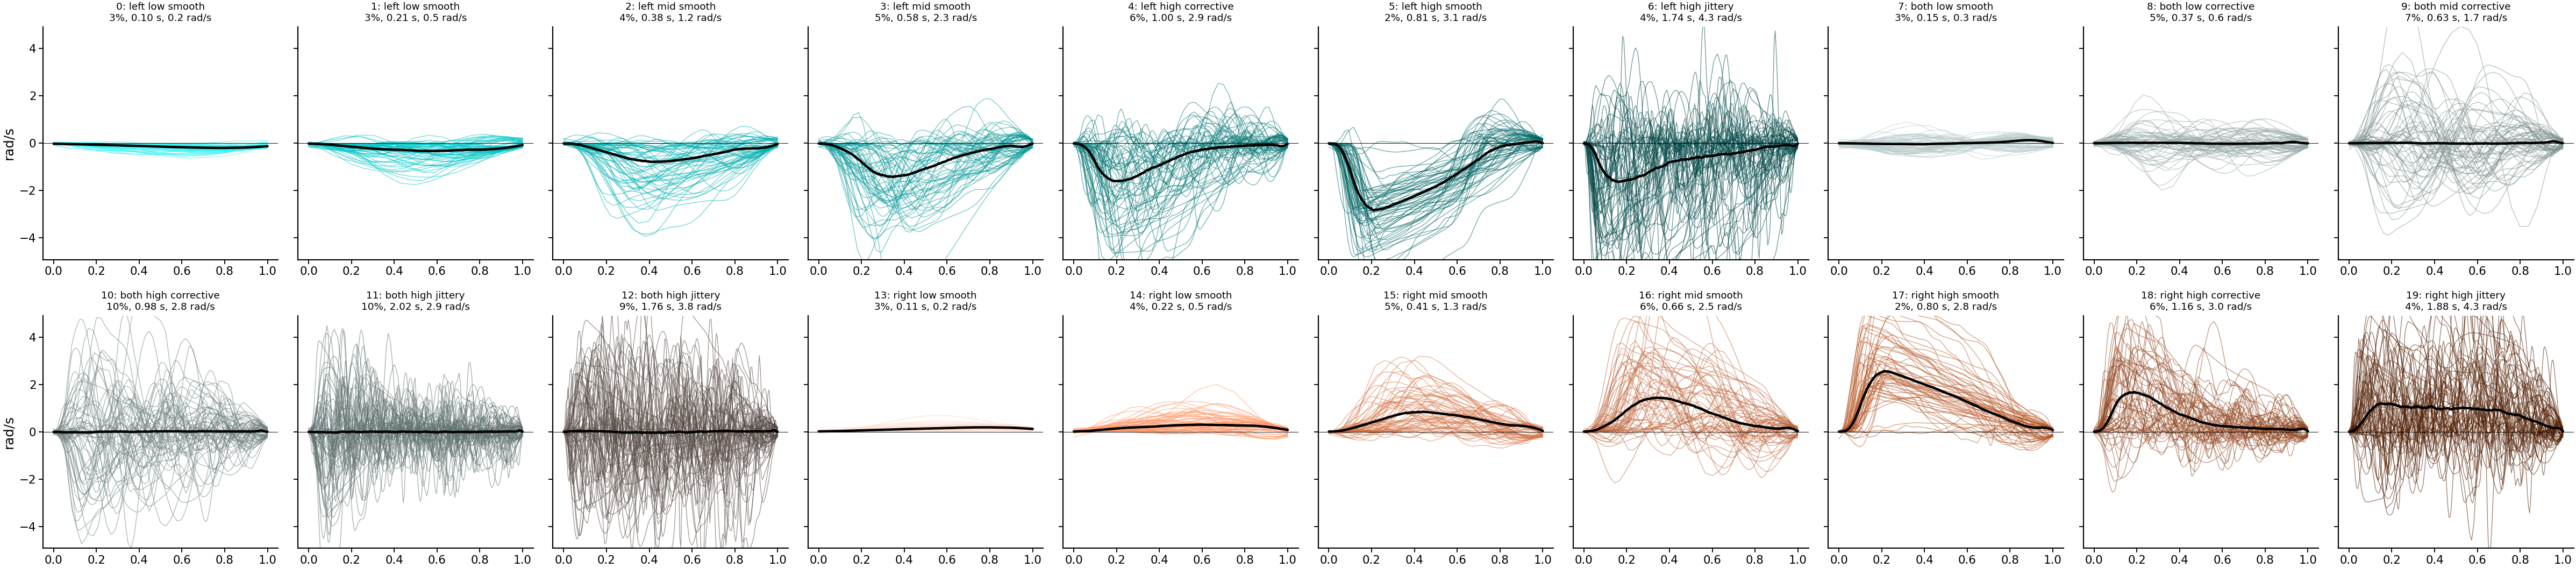

In [5]:
COL = wmc.colours(model)[1:]
D, K = model['desc'], model['K']
x = np.linspace(0, 1, wmc.NT); YL = np.percentile(np.abs(S), 99.5); rng = np.random.default_rng(0)
fig, axs = plt.subplots(2, K // 2, figsize=(2.2 * K / 2, 5), sharey=True)
for c, ax in enumerate(axs.flat):
    a = S[info.cluster == c]
    ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=COL[c], lw=.4, alpha=.6)
    ax.plot(x, np.median(a, 0), c='k', lw=1.5); ax.axhline(0, c='k', lw=.3); ax.set_ylim(-YL, YL)
    ax.set_title(f'{c}: {D.label[c]}\n{D.fraction[c]:.0%}, {D.duration_s[c]:.2f} s, {D.peak_rad_s[c]:.1f} rad/s', fontsize=6)
for ax in axs[:, 0]: ax.set_ylabel('rad/s')
plt.tight_layout()

## The three state sets and their colours (hue = stimulus side reported: teal left, orange right, grey balanced; lightness = vigor; hatch = jitter)

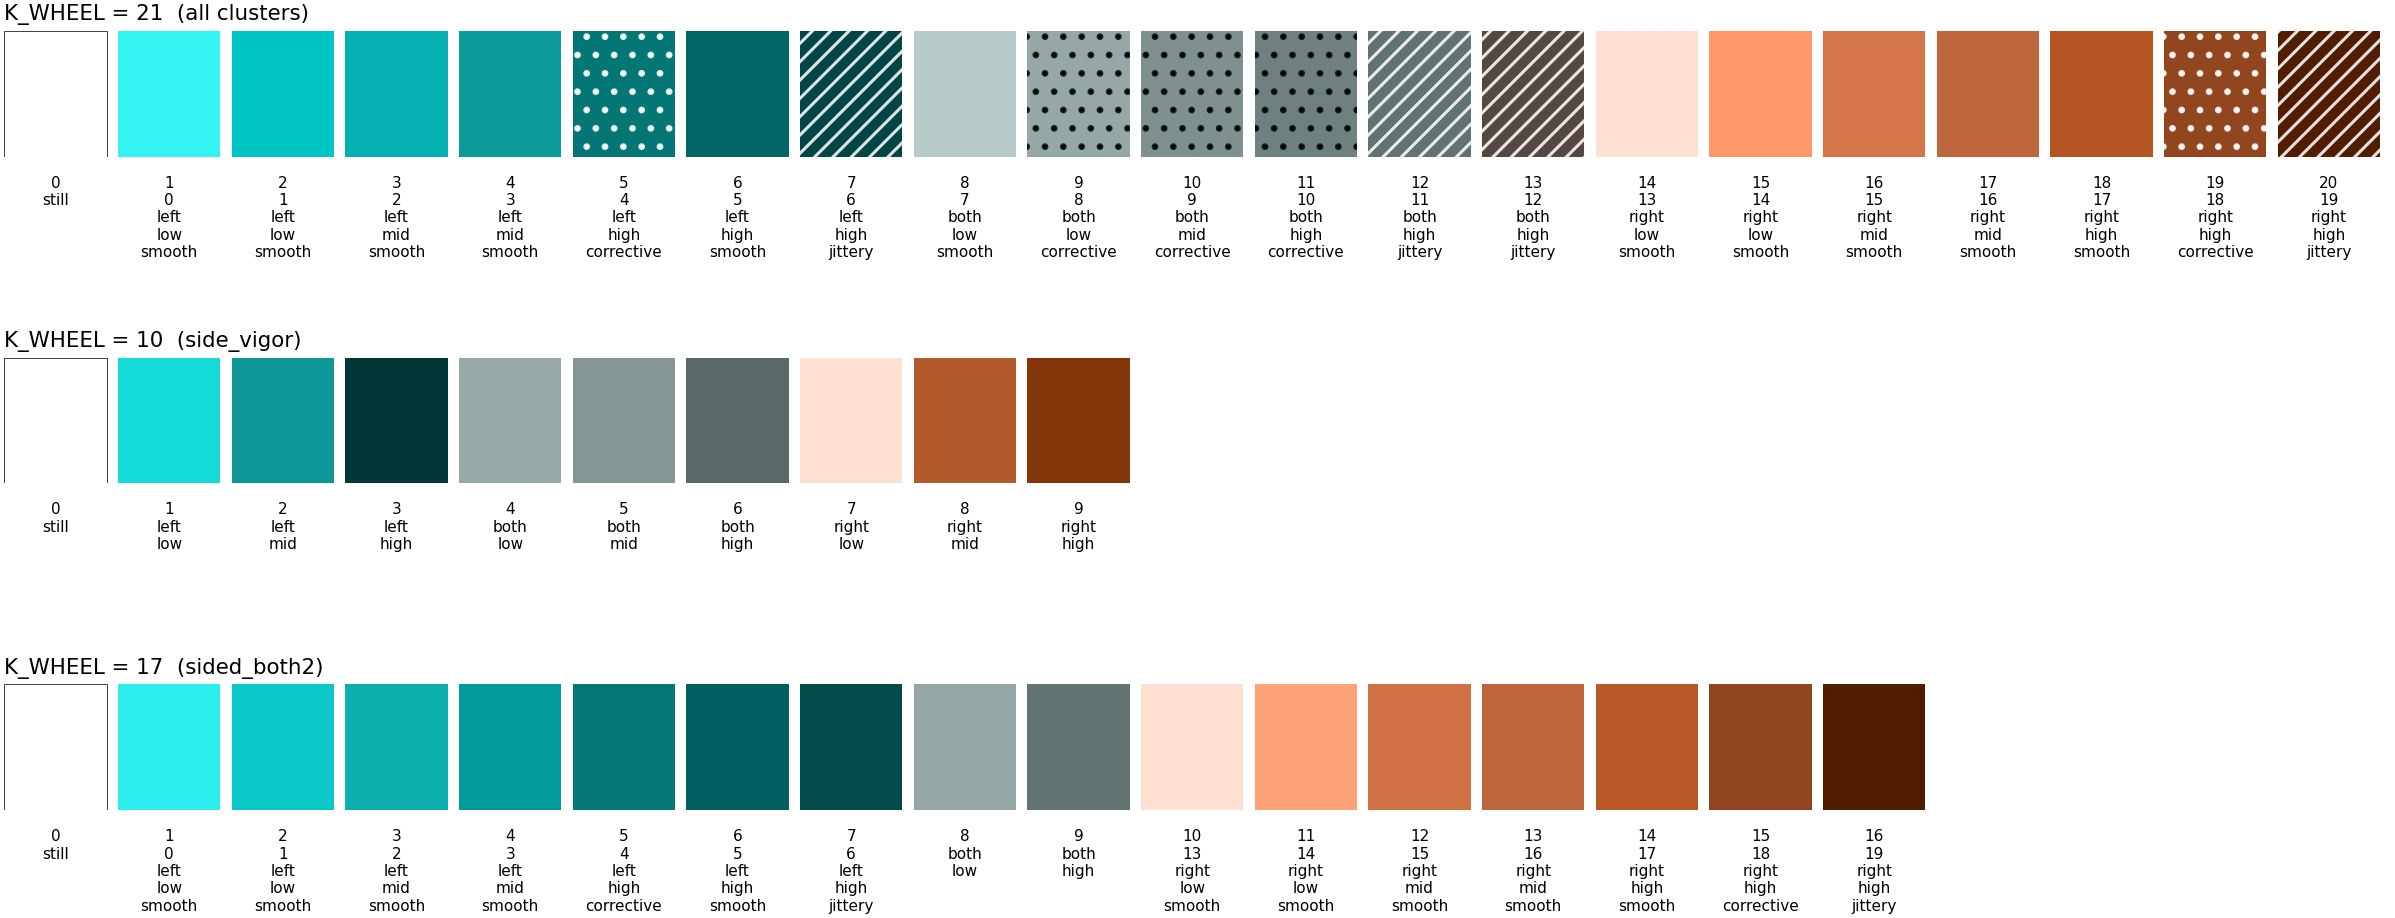

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(14, 4.6), gridspec_kw=dict(hspace=1.6))
for ax, g in zip(axs, [None, *wmc.GROUPINGS]):
    names, cols = wmc.state_names(model, g), wmc.colours(model, g)
    jit = [''] + ([wmc.HATCH[j] for j in D.jitter] if g is None else [''] * (len(names) - 1))
    for i, (n, c) in enumerate(zip(names, cols)):
        ax.add_patch(Rectangle((i, 0), .9, 1, facecolor=c, hatch=jit[i], edgecolor=ps.hatch_ink(c), lw=.3 if i == 0 else 0))
        ax.text(i + .45, -.15, f'{i}\n' + n.replace(' ', '\n'), ha='center', va='top', fontsize=5)
    ax.set(xlim=(0, 21), ylim=(0, 1), xticks=[], yticks=[])
    ax.set_title(f'K_WHEEL = {wmc.k_of(model, g)}  ({g or "all clusters"})', fontsize=7, loc='left')
    for s_ in ax.spines.values(): s_.set_visible(False)

## Write the states files

In [7]:
cfg = sp.resolve(DATASET, 'both_paws', 'own')
sessions = [s for s in sp.sessions_with_inputs(cfg) if wmc.has_movements(DATASET, *s)]
print(f'{len(sp.sessions_with_inputs(cfg))} sessions with paw / whisker / lick states, {len(sessions)} with cached movements')
if WRITE:
    print(wmc.write_states(DATASET, model, sessions, n_jobs=N_JOBS, overwrite=OVERWRITE), '(number of files written per session: count)')
files = [f for f in os.listdir(wmc.states_dir(DATASET)) if f.startswith('most_likely_states_')]
print(pd.Series([f.split('_')[3] for f in files]).value_counts().rename('files per K_WHEEL').to_dict())

332 sessions with paw / whisker / lick states, 332 with cached movements


{3: 332} (number of files written per session: count)
{'21': 332, '17': 332, '10': 332}


In [8]:
# check one session: frames match the paw states' frames, and the states agree across the three sets
m, e = sessions[0]
st = {k: np.load(wmc.states_dir(DATASET) + f'most_likely_states_{k}_{m}{e}.npy') for k in (21, 10, 17)}
paw = np.load(cfg['states_dir'] + f"most_likely_states_{cfg['k']}_{m}{e}.npy")
print(f'{m} {e[:8]}: {st[21].shape[1]:,} wheel frames, all paw frames present: {np.isin(paw[1], st[21][1]).all()}; '
      f'in a movement {np.mean(st[21][0] > 0):.0%}; still identical across sets: '
      f'{(st[21][0] == 0).sum() == (st[10][0] == 0).sum() == (st[17][0] == 0).sum()}')
occ = pd.DataFrame({k: pd.Series(v[0]).value_counts(normalize=True).sort_index() for k, v in st.items()})
occ.round(3).T

DY_011 36280321: 194,246 wheel frames, all paw frames present: True; in a movement 25%; still identical across sets: True


,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
21,0.751,0.001,0.002,0.004,0.013,0.019,0.024,0.007,0.001,0.003,...,0.028,0.028,0.013,0.002,0.003,0.009,0.018,0.021,0.036,0.006
10,0.751,0.002,0.017,0.050,0.004,0.012,0.069,0.005,0.027,0.062,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,0.751,0.001,0.002,0.004,0.013,0.019,0.024,0.007,0.004,0.081,...,0.003,0.009,0.018,0.021,0.036,0.006,NaN,NaN,NaN,NaN
